In [1]:
# Imports

import os

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from dotenv import load_dotenv
from sqlalchemy import URL, create_engine

In [2]:
# Load

load_dotenv()

url = URL.create(
    "postgresql+psycopg",
    username=os.environ["PGUSER"],
    password=os.getenv("PGPASSWORD") or None,
    host=os.environ["PGHOST"],
    port=int(os.environ["PGPORT"]),
    database=os.environ["PGDATABASE"],
)

engine = create_engine(url)

query = """
WITH precipitation_2024 AS (
    SELECT
          (time AT TIME ZONE 'America/Edmonton')::date AS day,
           SUM(precipitation) AS precip_2024
      FROM practice_013.weather_hourly
     WHERE time >= TIMESTAMPTZ '2024-01-01 00:00:00 America/Edmonton'
       AND time <  TIMESTAMPTZ '2025-01-01 00:00:00 America/Edmonton'
     GROUP BY (time AT TIME ZONE 'America/Edmonton')::date
),

precipitation_2025 AS (
    SELECT
          (time AT TIME ZONE 'America/Edmonton')::date AS day,
           SUM(precipitation) AS precip_2025
      FROM practice_013.weather_hourly
     WHERE time >= TIMESTAMPTZ '2025-01-01 00:00:00 America/Edmonton'
       AND time <  TIMESTAMPTZ '2026-01-01 00:00:00 America/Edmonton'
     GROUP BY (time AT TIME ZONE 'America/Edmonton')::date
),

daily_comparison AS (
    SELECT
          COALESCE(TO_CHAR(a.day, 'MM-DD'), TO_CHAR(b.day, 'MM-DD')) AS month_day,
        a.precip_2024,
        b.precip_2025
     FROM precipitation_2024 a
     FULL OUTER JOIN precipitation_2025 b
       ON TO_CHAR(a.day, 'MM-DD') = TO_CHAR(b.day, 'MM-DD')
)

SELECT
       month_day AS date,
       SUM(COALESCE(precip_2024, 0)) OVER (ORDER BY month_day) AS "2024",
       SUM(COALESCE(precip_2025, 0)) OVER (ORDER BY month_day) AS "2025"
  FROM daily_comparison
 ORDER BY month_day;
"""

df = pd.read_sql_query(query, engine)

df.head()

,date,2024,2025
0,01-01,2.9,1.2
1,01-02,2.9,1.2
2,01-03,2.9,1.2
3,01-04,3.0,2.2
4,01-05,4.0,2.2


In [3]:
# Inspect

# Structure
print(df["date"].min(), "to", df["date"].max(), "\n")
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Dates:", df["date"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Dates:", not df["date"].is_monotonic_increasing)

01-01 to 12-31 

Shape: (366, 3) 

Dtypes:
date        str
2024    float64
2025    float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Dates: False 

Non-Monotonic Dates: False


In [4]:
df[["2024", "2025"]].describe().T

,count,mean,std,min,25%,50%,75%,max
2024,366.0,262.256011,173.848442,2.9,77.7,300.05,441.10,503.5
2025,366.0,253.531421,194.358889,1.2,47.0,247.55,443.65,521.3


In [5]:
# Additional Inspect: Leap Year in 2024

df.loc[df["date"].eq("02-28") | df["date"].eq("02-29") | df["date"].eq("03-01")]

,date,2024,2025
58,02-28,40.6,19.9
59,02-29,42.1,19.9
60,03-01,44.5,19.9


In [6]:
# Clean
# No clean required after inspection.

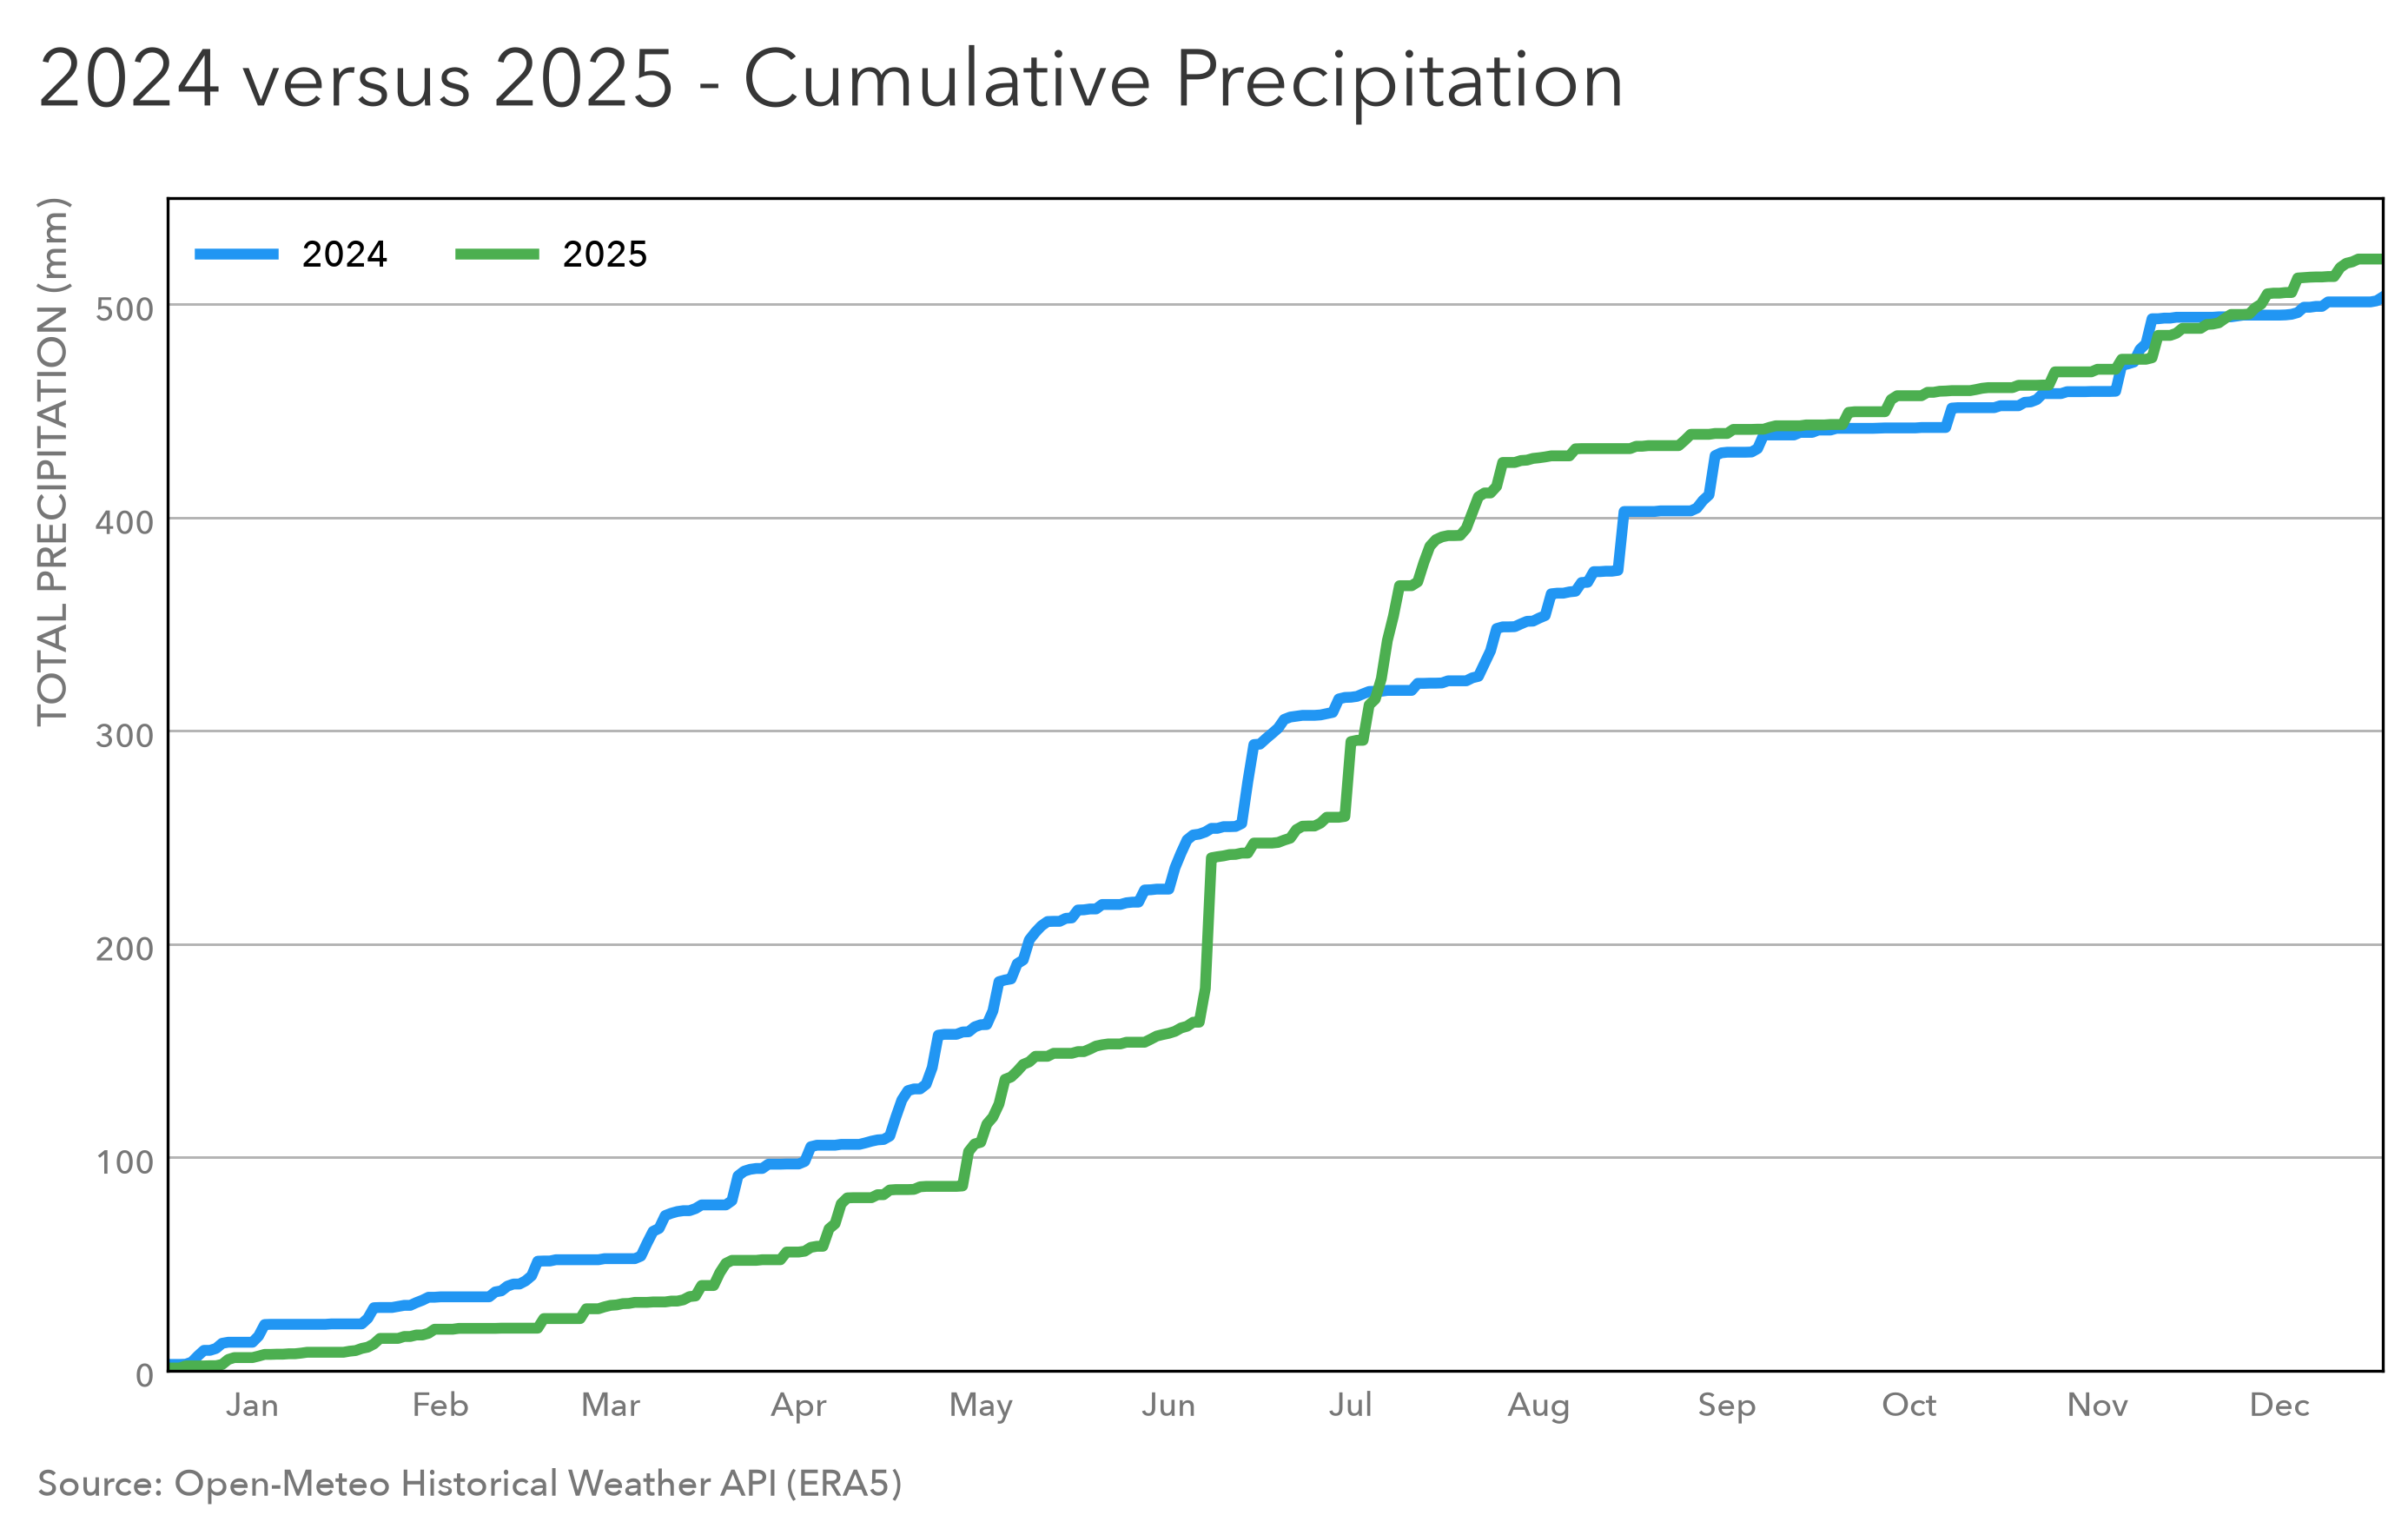

In [34]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, ax = plt.subplots(figsize = (10, 6), dpi = 300)

fig.subplots_adjust(
    left = 0.10,
    right = 0.95,
    top = 0.85,
    bottom = 0.10
)

STRUCTURE = "#777777"
GRID = "#B3B3B3"
BLUE = "#2196F3"
GREEN = "#4CAF50"
TITLE = "#363636"

# Plot

line2024, = ax.plot(df["date"], df["2024"], linewidth = 3, color = BLUE, label = "2024")
line2025, = ax.plot(df["date"], df["2025"], linewidth = 3, color = GREEN, label = "2025")

# Scale & Axes

ax.set_ylim(0, 550)

ax.set_xlim("01-01", df["date"].max())

ax.set_ylabel("TOTAL PRECIPITATION (mm)", loc = "top", fontsize = 11, fontweight = 500, color = STRUCTURE)

# Ticks

ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[15]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.tick_params(axis = "x", labelsize = 9, length = 0, labelcolor = STRUCTURE)
ax.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)

# Styling

ax.legend(frameon = False, ncol = 2, fontsize = 10)

ax.set_axisbelow(True)
ax.grid(axis = "y",which = "major", color = GRID, linewidth=0.7)

# Composition

fig.suptitle("2024 versus 2025 - Cumulative Precipitation", x = 0.05, y = 0.96, ha = "left", va = "top", fontweight = 400, fontsize = 22, color = TITLE)

fig.text(0.05, 0.02, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 10, color = STRUCTURE)

# Output

#fig.savefig("outputs/cumulative-precipitation-comparison-2024-2025.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()